<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/04_provenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Provenance (C2PA) channel stress test

Manuscript sections 2.2 and 3.2.3, research question 1: do C2PA content credentials survive social-media processing?

Every test image is signed with a test certificate authority, as a generator or drawing app would:
AI images declare `trainedAlgorithmicMedia`, human images `digitalCreation` (the best case, where every tool attaches credentials).
Each signed file then goes through the same transforms as the CNN and watermark tests (JPEG 90/70/50/30, WebP, downscaling, recompression)
and is checked three ways:

- **stripped**: the re-encoded file as a platform serves it (the encoder writes no C2PA data),
- **kept**: the platform copies the original manifest into the re-encoded file; the manifest is there, but its hash no longer matches the changed pixels,
- **soft binding**: the image is looked up by perceptual hash in a repository of all signed images (C2PA's way to recover stripped credentials).

Two forgeries are also tested: copying a manifest from an image of the other class (transplant), and signing with the wrong claim using a certificate that is not trusted.

Before starting: notebook 01 has saved `thesis-data/harmonized.zip` to Drive. **No GPU needed**: Runtime > Change runtime type > **CPU**.
Takes about 5-10 minutes.

## 1. Get the code

In [1]:
%cd /content
!rm -rf repo
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd /content/repo
!pip install -q -e ".[train,provenance,dev]"

/content
Cloning into 'repo'...
remote: Enumerating objects: 447, done.
remote: Counting objects: 100% (211/211), done.
remote: Compressing objects: 100% (158/158), done.
remote: Total 447 (delta 122), reused 73 (delta 44), pack-reused 236 (from 1)
Receiving objects: 100% (447/447), 6.73 MiB | 15.39 MiB/s, done.
Resolving deltas: 100% (222/222), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done


## 2. Restore the prepared data from Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
ZIP = "/content/drive/MyDrive/thesis-data/harmonized.zip"
if not os.path.exists(ZIP):
    raise FileNotFoundError(f"{ZIP} not found: run notebook 01 through step 8 first, it saves the prepared data there")
!unzip -qo $ZIP -d .
!wc -l data/harmonized/val.csv data/harmonized/test.csv

Mounted at /content/drive
  2981 data/harmonized/val.csv
  2993 data/harmonized/test.csv
  5974 total


## 3. Run the provenance stress test
Signs and verifies every test image under every transform, then sets the soft-binding match threshold on the (unsigned) validation images
so that at most 1% of images that were never registered would wrongly match a registered one. Results are written to Google Drive (`thesis-data/provenance/`).

In [3]:
!mkdir -p /content/drive/MyDrive/thesis-data/provenance && rm -rf outputs/provenance && ln -s /content/drive/MyDrive/thesis-data/provenance outputs/provenance
!python scripts/provenance_test.py

signing and verifying 2992 test images under 9 conditions
hashing 2980 unsigned validation images for the soft-binding threshold
soft-binding threshold = 11 bits (unregistered images wrongly matched at most 1% under every condition)
           clean: credential usable  stripped 100.0%  kept 100.0%  soft_binding 100.0%
        jpeg_q90: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
        jpeg_q70: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
        jpeg_q50: credential usable  stripped 0.0%  kept 0.0%  soft_binding 99.9%
        jpeg_q30: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
        webp_q80: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
      resize_0.5: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
     resize_0.25: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
   recompress_x3: credential usable  stripped 0.0%  kept 0.0%  soft_binding 100.0%
  attack transpla

## 4. Results
**valid**: the credential verifies (present, signature and hash intact, trusted signer), so the image can be attributed from it.
**invalid**: a manifest is there but no longer matches the image. **absent**: no manifest at all.
For soft binding, **recovered** is the share of images matched back to their own credential, **wrong match** the share matched to another image's credential,
and **false match** the share of never-registered validation images that matched something.

Credential usable (valid with the right claim, or recovered by soft binding):


policy,stripped,kept,soft_binding
condition,,,
clean,1.0,1.0,1.0000
jpeg_q90,0.0,0.0,0.9997
jpeg_q70,0.0,0.0,0.9997
jpeg_q50,0.0,0.0,0.9993
jpeg_q30,0.0,0.0,0.9997
webp_q80,0.0,0.0,0.9997
resize_0.5,0.0,0.0,0.9997
resize_0.25,0.0,0.0,0.9997
recompress_x3,0.0,0.0,0.9997


Status when the platform keeps the manifest:


,valid_rate,invalid_rate,absent_rate
condition,,,
clean,1.0,0.0,0.0
jpeg_q90,0.0,1.0,0.0
jpeg_q70,0.0,1.0,0.0
jpeg_q50,0.0,1.0,0.0
jpeg_q30,0.0,1.0,0.0
webp_q80,0.0,1.0,0.0
resize_0.5,0.0,1.0,0.0
resize_0.25,0.0,1.0,0.0
recompress_x3,0.0,1.0,0.0


Soft binding (threshold 11 of 64 bits, repository of 2992 images):


,recovered,wrong_match_rate,false_match_rate
condition,,,
clean,1.0000,0.0000,0.0074
jpeg_q90,0.9997,0.0000,0.0077
jpeg_q70,0.9997,0.0003,0.0081
jpeg_q50,0.9993,0.0003,0.0081
jpeg_q30,0.9997,0.0003,0.0074
webp_q80,0.9997,0.0000,0.0081
resize_0.5,0.9997,0.0000,0.0074
resize_0.25,0.9997,0.0000,0.0077
recompress_x3,0.9997,0.0000,0.0084


Forgery attacks on clean files:


,attack,n,valid_rate,untrusted_rate,invalid_rate,absent_rate
0,transplant,2992,0.0,0.0,1.0,0.0
1,self_signed,2992,0.0,1.0,0.0,0.0


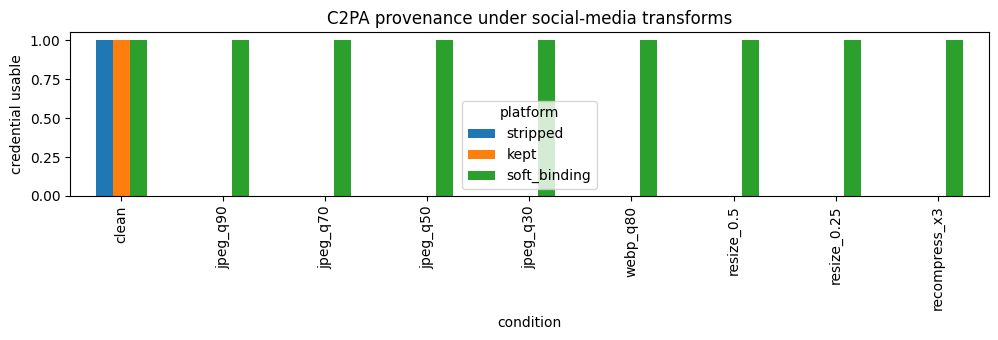

In [4]:
import json, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("outputs/provenance/results.csv")
order = df.condition.unique()
both = df.groupby(["policy", "condition"], sort=False).mean(numeric_only=True).reset_index()  # AI and human pooled (equal n)
print("Credential usable (valid with the right claim, or recovered by soft binding):")
display(both.pivot(index="condition", columns="policy", values="correct_rate").loc[order, ["stripped", "kept", "soft_binding"]].round(4))
print("Status when the platform keeps the manifest:")
display(both[both.policy == "kept"].set_index("condition")[["valid_rate", "invalid_rate", "absent_rate"]].loc[order].round(4))
sb = json.load(open("outputs/provenance/softbinding.json"))
print(f"Soft binding (threshold {sb['threshold_bits']} of 64 bits, repository of {sb['repository_size']} images):")
display(both[both.policy == "soft_binding"].set_index("condition")[["correct_rate", "wrong_match_rate", "false_match_rate"]]
        .rename(columns={"correct_rate": "recovered"}).loc[order].round(4))
print("Forgery attacks on clean files:")
display(pd.read_csv("outputs/provenance/attacks.csv").round(4))
ax = both.pivot(index="condition", columns="policy", values="correct_rate").loc[order, ["stripped", "kept", "soft_binding"]].plot.bar(figsize=(10, 3.5), ylim=(0, 1.05))
ax.set_ylabel("credential usable"); ax.set_title("C2PA provenance under social-media transforms"); ax.legend(title="platform")
plt.tight_layout()

## 5. What a credential looks like
The manifest c2pa writes into one signed AI test image, and what a verifier reports before and after a JPEG q90 re-encode with the manifest copied over.

In [5]:
# pip install -e only takes effect in new processes (the !python scripts above), not in this
# already-running kernel, so point it at the package source directly
import sys
if "/content/repo/src" not in sys.path:
    sys.path.insert(0, "/content/repo/src")
import io, c2pa
from PIL import Image
from attribution.data.splits import read_split
from attribution.signals import provenance as prov
from attribution.transforms.social_media import encode
creds = prov.make_credentials()
ctx = prov.context([creds.root_pem])
r = next(r for r in read_split("data/harmonized/test.csv") if r.label == 1)
signed, store = prov.sign(open(r.path, "rb").read(), "image/jpeg", "trainedAlgorithmicMedia", prov.signer(creds), ctx)
with c2pa.Reader("image/jpeg", io.BytesIO(signed), context=ctx) as rd:
    print(json.dumps(rd.get_active_manifest(), indent=1)[:1500])
print("\nsigned file:", prov.verify(signed, "image/jpeg", ctx))
reencoded = encode(Image.open(io.BytesIO(signed)), "JPEG", 90)
print("JPEG q90, stripped:", prov.verify(reencoded, "image/jpeg", ctx))
print("JPEG q90, manifest kept:", prov.verify(prov.carry_manifest(reencoded, "image/jpeg", prov.jpeg_manifest_segments(signed), store), "image/jpeg", ctx))

{
 "claim_generator_info": [
  {
   "name": "thesis-attribution",
   "version": "0.1",
   "org.contentauth.c2pa_rs": "0.91.3"
  }
 ],
 "instance_id": "xmp.iid:6aaa0456-1cc9-4513-8928-a343cfece85b",
 "assertions": [
  {
   "label": "c2pa.actions.v2",
   "data": {
    "actions": [
     {
      "action": "c2pa.created",
      "digitalSourceType": "http://cv.iptc.org/newscodes/digitalsourcetype/trainedAlgorithmicMedia"
     }
    ]
   }
  }
 ],
 "signature_info": {
  "alg": "Es256",
  "issuer": "Thesis test CA",
  "common_name": "Signer",
  "cert_serial_number": "474801615710354218129476857010115432534558540372"
 },
 "label": "urn:c2pa:6380f516-0f2f-405c-848c-9db4d2693201",
 "claim_version": 2
}

signed file: ProvenanceResult(status=<ProvenanceStatus.VALID: 'valid'>, claims_ai=True)
JPEG q90, stripped: ProvenanceResult(status=<ProvenanceStatus.ABSENT: 'absent'>, claims_ai=None)
JPEG q90, manifest kept: ProvenanceResult(status=<ProvenanceStatus.INVALID: 'invalid'>, claims_ai=True)
